# Learned selector at a fixed budget (10 Nov)

**Question.** At each landscape cell's budget k, using all k queries, can a seed-set score fitted where good sets live pick sets that beat the best hand-made rule?

The frozen pooled score was fitted at round 1's settings, on sets drawn from a random pool (plain random sets, the pool's extreme tail and degree-matched contrasts), with single-run pass/fail labels. Rule-built sets sit far outside that range: top degree is about 11–13 SD above the average random set in seed degree, while the farthest training sets reach about 5 on ER. The best rule also changes with the regime.

**Steps** (`learned_selector.py`; each resumes where it stopped):
1. **Weights** — how much do fitted weights move across the 27 standard landscape cells, and does a score fitted in one cell rank sets in another? Landscape data only; this section runs as soon as the notebook opens.
2. **Constructed sets** — on the first landscape pair of each cell, sets that span random to rule-built (rules, best-of screens, degree tilts up to γ = 8, quantile picks, swap paths from random sets toward each rule's set), each run on the pair's saved B and the landscape's 10 redraws of B. The landscape's 100 redrawn random sets join them, so every set has a label averaged over the same 11 Bs.
3. **Rounds** — per cell, fit the selector (logistic in the four core z-scores plus degree squared, on mean accuracy over the 11 Bs), search near the rules within the labelled sets' range, run the proposals on the same Bs, refit; two rounds. Then the final selector.
4. **Fresh pairs** — 10 new pairs per cell at the same k: the final selector's set against every rule (the best rule fixed in advance from the landscape), the frozen score's set built the same way, the best of 1,000 random sets by the frozen score, and random sets.

Run steps 2–4 from the repository root with `python -m selection_rule_comparison.learned_selector --all` (or one step at a time; see the module's docstring). Sections 2–4 below fill in as results arrive; rerun the notebook to update them.

In [1]:
import os
import sys
import tempfile
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'sgm_matplotlib_cache'))

import importlib

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / 'experiment_common').is_dir())
if ROOT.name == 'selection_rule_comparison':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from selection_rule_comparison import landscape as L
from selection_rule_comparison import learned_selector as LS
L = importlib.reload(L)
LS = importlib.reload(LS)   # picks up edits to learned_selector.py without restarting the kernel

design = LS.read_design()
display(LS.status(design))

pd.set_option('display.max_rows', 300)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 250)

constructed   round 1   round 2  \
model    algorithm   mean degree ρ   budget                                     
ER       Percolation 8           0.7 13      1045 of 1045  44 of 44  44 of 44   
                     16          0.4 51      1034 of 1034  44 of 44  44 of 44   
                     32          0.3 93      1045 of 1045  44 of 44  44 of 44   
         SGM (FAQ)   32          0.3 71        957 of 957  44 of 44  44 of 44   
                     8           0.5 58        957 of 957  44 of 44  44 of 44   
                     16          0.3 143       957 of 957  44 of 44  44 of 44   
         GOAT        8           0.5 33      1045 of 1045  44 of 44  44 of 44   
                                 0.4 105     1045 of 1045  44 of 44  44 of 44   
                     16          0.3 117     1045 of 1045  44 of 44  44 of 44   
Chung-Lu Percolation 10          0.7 6       1045 of 1045  44 of 44  44 of 44   
                     16          0.4 54      1045 of 1045  44 of 44  44 of 44   
                     32          0.3 89      1034 of 1034  44 of 44  44 of 44   
         SGM (FAQ)   32          0.3 53        957 of 957  44 of 44  44 of 44   
                     10          0.5 31        968 of 968  44 of 44  44 of 44   
                     16          0.3 107       968 of 968  44 of 44  44 of 44   
         GOAT        10          0.5 12      1045 of 1045  44 of 44  44 of 44   
                                 0.4 47      1034 of 1034  44 of 44  44 of 44   
                     16          0.3 76      1034 of 1034  44 of 44  44 of 44   
PAPER    Percolation 8           0.7 3         847 of 847  44 of 44  44 of 44   
                     16          0.4 24      1045 of 1045  44 of 44  44 of 44   
                     32          0.3 47      1045 of 1045  44 of 44  44 of 44   
         SGM (FAQ)   32          0.3 48        957 of 957  44 of 44  44 of 44   
                     8           0.5 22        957 of 957  44 of 44  44 of 44   
                     16          0.3 53        957 of 957  44 of 44  44 of 44   
         GOAT        8           0.5 3         913 of 913  44 of 44  44 of 44   
                                 0.4 7       1045 of 1045  44 of 44  44 of 44   
                     16          0.3 36      1045 of 1045  44 of 44  44 of 44   

                                                  fresh final  
model    algorithm   mean degree ρ   budget                    
ER       Percolation 8           0.7 13      600 of 600   yes  
                     16          0.4 51      600 of 600   yes  
                     32          0.3 93      600 of 600   yes  
         SGM (FAQ)   32          0.3 71      550 of 550   yes  
                     8           0.5 58      550 of 550   yes  
                     16          0.3 143     550 of 550   yes  
         GOAT        8           0.5 33      600 of 600   yes  
                                 0.4 105     600 of 600   yes  
                     16          0.3 117     600 of 600   yes  
Chung-Lu Percolation 10          0.7 6       600 of 600   yes  
                     16          0.4 54      600 of 600   yes  
                     32          0.3 89      600 of 600   yes  
         SGM (FAQ)   32          0.3 53      550 of 550   yes  
                     10          0.5 31      550 of 550   yes  
                     16          0.3 107     550 of 550   yes  
         GOAT        10          0.5 12      600 of 600   yes  
                                 0.4 47      600 of 600   yes  
                     16          0.3 76      600 of 600   yes  
PAPER    Percolation 8           0.7 3       600 of 600   yes  
                     16          0.4 24      600 of 600   yes  
                     32          0.3 47      600 of 600   yes  
         SGM (FAQ)   32          0.3 48      550 of 550   yes  
                     8           0.5 22      550 of 550   yes  
                     16          0.3 53      550 of 550   yes  
         GOAT        8          

## 1. Do fitted weights move across cells?

For each standard landscape cell: test accuracy regressed on the four core z-scores over its random sets, with each pair's mean removed (single runs on the saved B; FAQ's 3 runs averaged). Slopes are accuracy per SD, with 95% intervals.

- **cosine with frozen**: how close the fitted direction is to the frozen weights' direction.
- **rank agreement with frozen**: Spearman between the fitted score and the frozen score over the cell's random sets.
- **degree-harmonic r**: the correlation of the two among random sets. When it is high, how a fit splits the credit between them is unstable.

In [2]:
sets = L.per_set()
quality = L.set_quality(L.draws(sets), sets)
weights = LS.weight_table(sets)
display(LS.show(weights[["model", "algorithm", "mean_degree", "rho", "budget", *LS.CORE, "R2", "cosine with frozen",
                         "rank agreement with frozen", "degree-harmonic r"]]))

degree  harmonic  pair_mass  uniqueness    R2  cosine with frozen  rank agreement with frozen  degree-harmonic r
model    algorithm   mean degree ρ   budget                                                                                                                  
ER       Percolation 8           0.7 13       -0.05      0.06       0.07        0.05  0.17                0.81                        0.97               0.92
                     16          0.4 51        0.02     -0.00       0.03        0.00  0.05                0.77                        0.98               0.89
                     32          0.3 93        0.02     -0.01      -0.01        0.00  0.01               -0.36                        0.71               0.77
         SGM (FAQ)   8           0.5 58        0.05      0.01      -0.00        0.02  0.13                0.60                        0.94               0.83
                     16          0.3 143       0.02     -0.01      -0.00        0.00  0.03                0.24                        0.84               0.64
                     32          0.3 71        0.08     -0.02      -0.02       -0.00  0.05                0.18                        0.88               0.84
         GOAT        8           0.4 105       0.02      0.00      -0.00        0.00  0.05                0.19                        0.81               0.70
                                 0.5 33        0.06      0.02       0.00       -0.01  0.08                0.43                        0.94               0.88
                     16          0.3 117       0.03     -0.01       0.00        0.00  0.05                0.06                        0.78               0.70
Chung-Lu Percolation 10          0.7 6        -0.10      0.15       0.12       -0.01  0.18                0.99                        0.99               0.84
                     16          0.4 54       -0.01      0.03       0.00        0.00  0.03                0.87                        0.98               0.88
                     32          0.3 89       -0.02      0.03       0.01        0.00  0.01                0.95                        0.88               0.90
         SGM (FAQ)   10          0.5 31       -0.04      0.12      -0.05        0.05  0.10                0.97                        0.99               0.82
                     16          0.3 107      -0.01      0.00       0.01        0.00  0.01                0.61                        0.77               0.85
                     32          0.3 53       -0.05      0.07      -0.00       -0.01  0.01                0.87                        0.50               0.90
         GOAT        10          0.4 47       -0.03      0.04      -0.01        0.00  0.02                0.92                        0.76               0.80
                                 0.5 12       -0.05      0.08      -0.01        0.02  0.03                0.97                        0.98               0.83
                     16          0.3 76       -0.02      0.01       0.00        0.00  0.01                0.95                        0.74               0.87
PAPER    Percolation 8           0.7 3        -0.04     -0.01      -0.01       -0.00  0.03                0.20                       -0.63               0.83
                     16          0.4 24       -0.06      0.09       0.05        0.00  0.04                0.99                        1.00               0.94
                     32          0.3 47        0.00      0.02      -0.00       -0.00  0.01                0.51                        0.93               0.89
         SGM (FAQ)   8           0.5 22        0.05      0.03      -0.03        0.04  0.08                0.78                        0.96               0.85
                     16          0.3 53        0.06     -0.01      -0.01        0.00  0.05                0.94                        0.98               0.88
                     32          0.3 48        0.05     -0.00       0.02       -0.02  0.04     

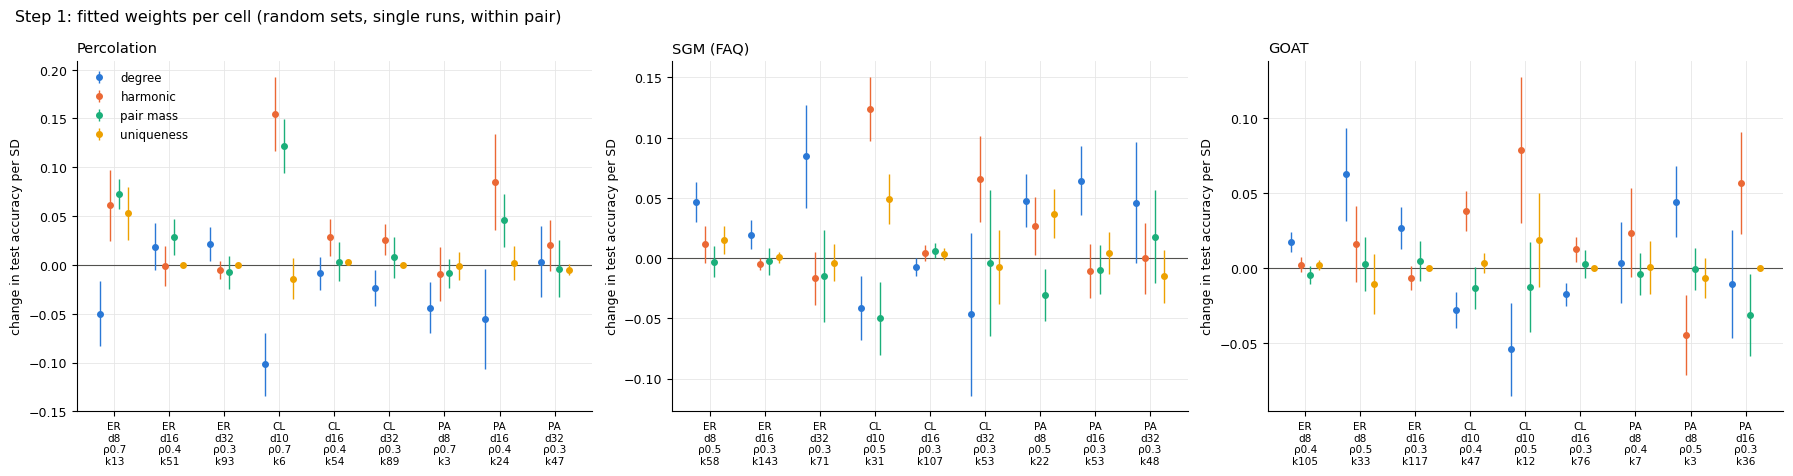

In [3]:
LS.plot_weights(weights)
plt.show()

### Does a score fitted in one cell rank sets in another?

Rows: the score fitted on a cell's pairs 1–4 (as above), plus the frozen score and degree alone. Columns: the cell it is tested on. Values: Spearman with mean accuracy over the 11 Bs of the test cell's 100 redrawn sets (pair 0, never used to fit). The diagonal is each cell's own fit on its own held-out pair. Cells are grouped by algorithm (solid lines) and graph model (dotted).

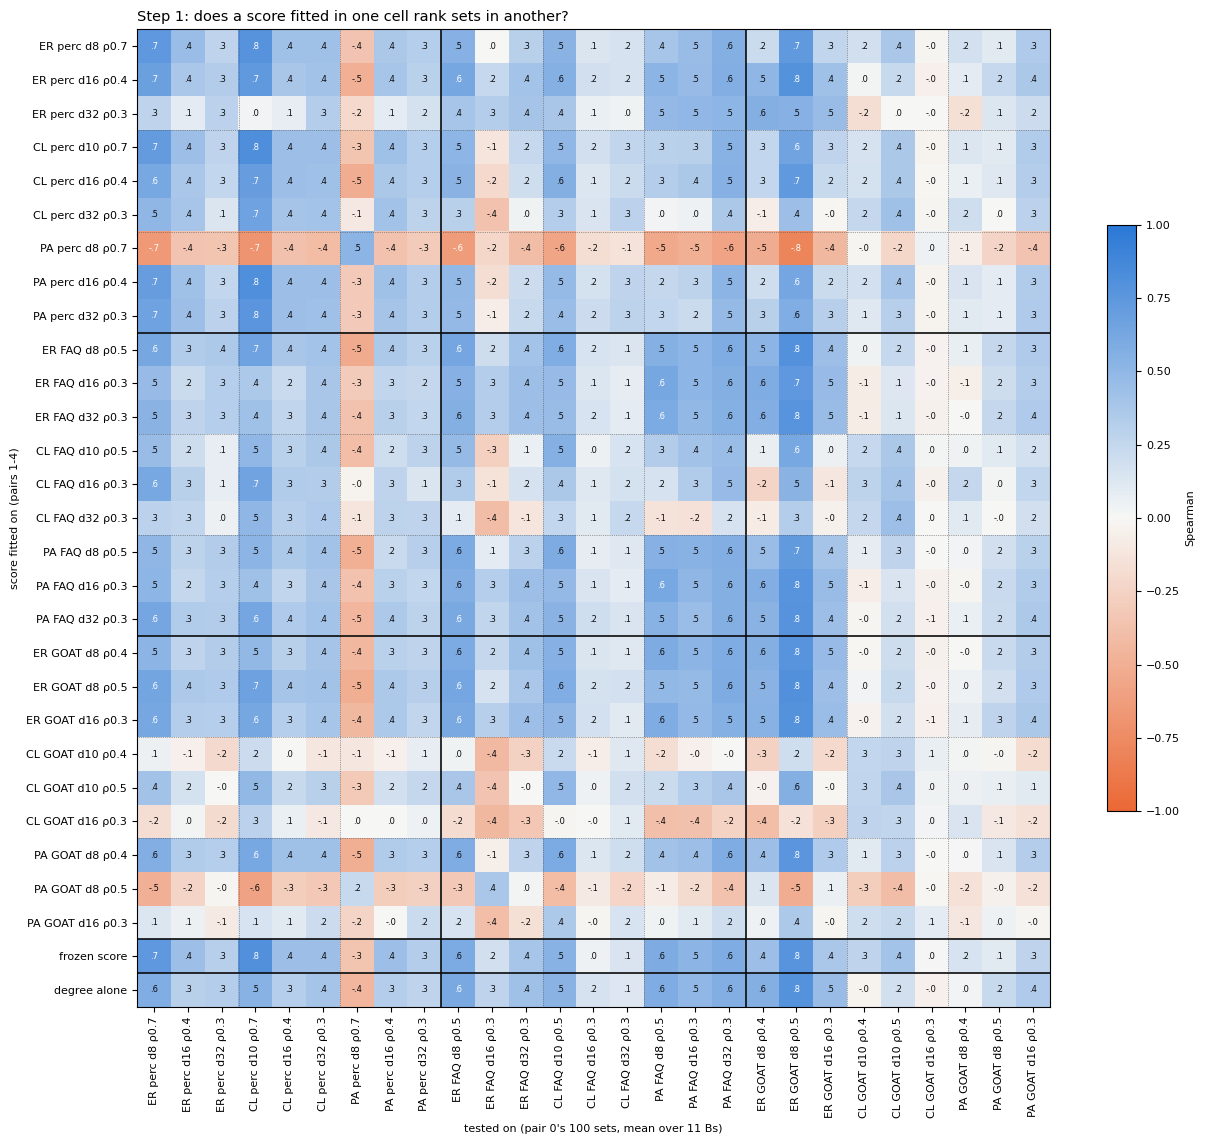

,own fit,frozen score,degree alone,"other cells, median","other cells, best",best source
target cell,,,,,,
ER perc d8 ρ0.7,0.74,0.74,0.57,0.64,0.72,CL perc d10 ρ0.7
ER perc d16 ρ0.4,0.37,0.44,0.30,0.41,0.45,ER perc d8 ρ0.7
ER perc d32 ρ0.3,0.28,0.31,0.33,0.26,0.33,ER perc d16 ρ0.4
CL perc d10 ρ0.7,0.82,0.80,0.53,0.71,0.80,PA perc d16 ρ0.4
CL perc d16 ρ0.4,0.43,0.43,0.32,0.41,0.44,CL perc d10 ρ0.7
CL perc d32 ρ0.3,0.41,0.44,0.40,0.43,0.44,PA perc d16 ρ0.4
PA perc d8 ρ0.7,0.52,-0.35,-0.45,-0.33,-0.10,CL perc d32 ρ0.3
PA perc d16 ρ0.4,0.43,0.43,0.32,0.38,0.43,CL perc d10 ρ0.7
PA perc d32 ρ0.3,0.32,0.32,0.27,0.30,0.33,PA perc d16 ρ0.4


In [4]:
matrix = LS.transfer_matrix(sets, quality)
LS.plot_transfer(matrix)
plt.show()
display(LS.transfer_summary(matrix).round(2))

### What step 1 shows

- **Refitting per cell changes little within the random sets' range.** On the held-out pair, a cell's own fit ranks sets about as well as the frozen score. The median difference is +0.03 for FAQ, −0.02 for GOAT and 0.00 for percolation. Own fits are better by more than 0.05 in 7 of 27 cells and worse in 4.
- **The exceptions:**
  - PAPER percolation at 3 seeds: the own fit ranks at 0.52 against −0.35 for the frozen score, which ranks backwards there.
  - Gains of 0.12–0.14 for ER FAQ at d16, ρ 0.3 and ER GOAT at d8, ρ 0.4.
  - The PAPER GOAT cells, where single-run refits at 3–36 seeds are mostly noise and do worse than the frozen score.
- **Weights carry over between cells for percolation and FAQ, not for GOAT.** Fits from the other cells of the same algorithm rank at a median 0.41 (percolation) and 0.47 (FAQ), close to the cells' own fits (0.43 and 0.50). For GOAT they rank at 0.09 against 0.25: GOAT's good sets depend on the graph model.
- **The individual weights are unstable; their combination is not.**
  - Among random sets, degree and harmonic centrality correlate at r = 0.64–0.94 (median 0.86), so fits split the credit between them differently from cell to cell. Degree's slope is positive in 14 cells and negative in 13, and the cosine with the frozen weights ranges from −0.84 to 0.99.
  - Yet the fitted and frozen scores rank random sets alike in most cells.
  - This instability is what an optimizer exploits once it can move degree and harmonic apart (the 21 October pilot).

So the room for a better selector is not inside the random sets' range. It is in the region the rules reach, which steps 2–4 label and test.

## 2. Labelled sets from random to rule-built (step 2)

Pair 0 of each cell: mean test accuracy over the saved B and its 10 redraws against seed degree (z against random sets).
- **Grey:** the landscape's 100 redrawn random sets.
- **Colours:** constructed sets (tilts, quantile picks, screens, swap paths toward each rule).
- **Orange shapes:** round 1's rules.
- **Black stars:** the selector's proposals (step 3).

Does quality keep rising past the random sets' range, level off, or turn down?

family
path         735
proposal     216
quantile     783
random      2700
rule         124
screen        70
tilt         749


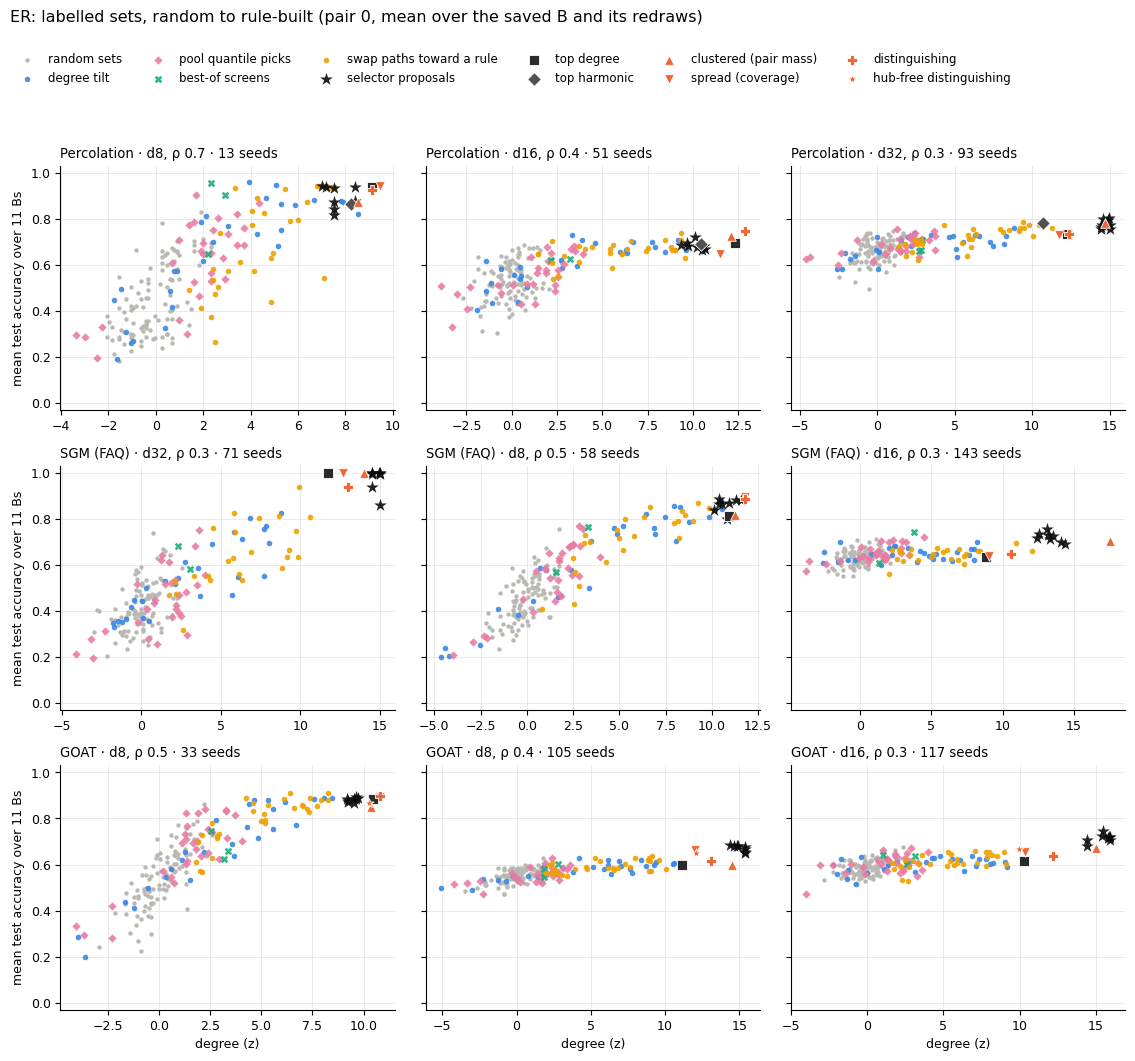

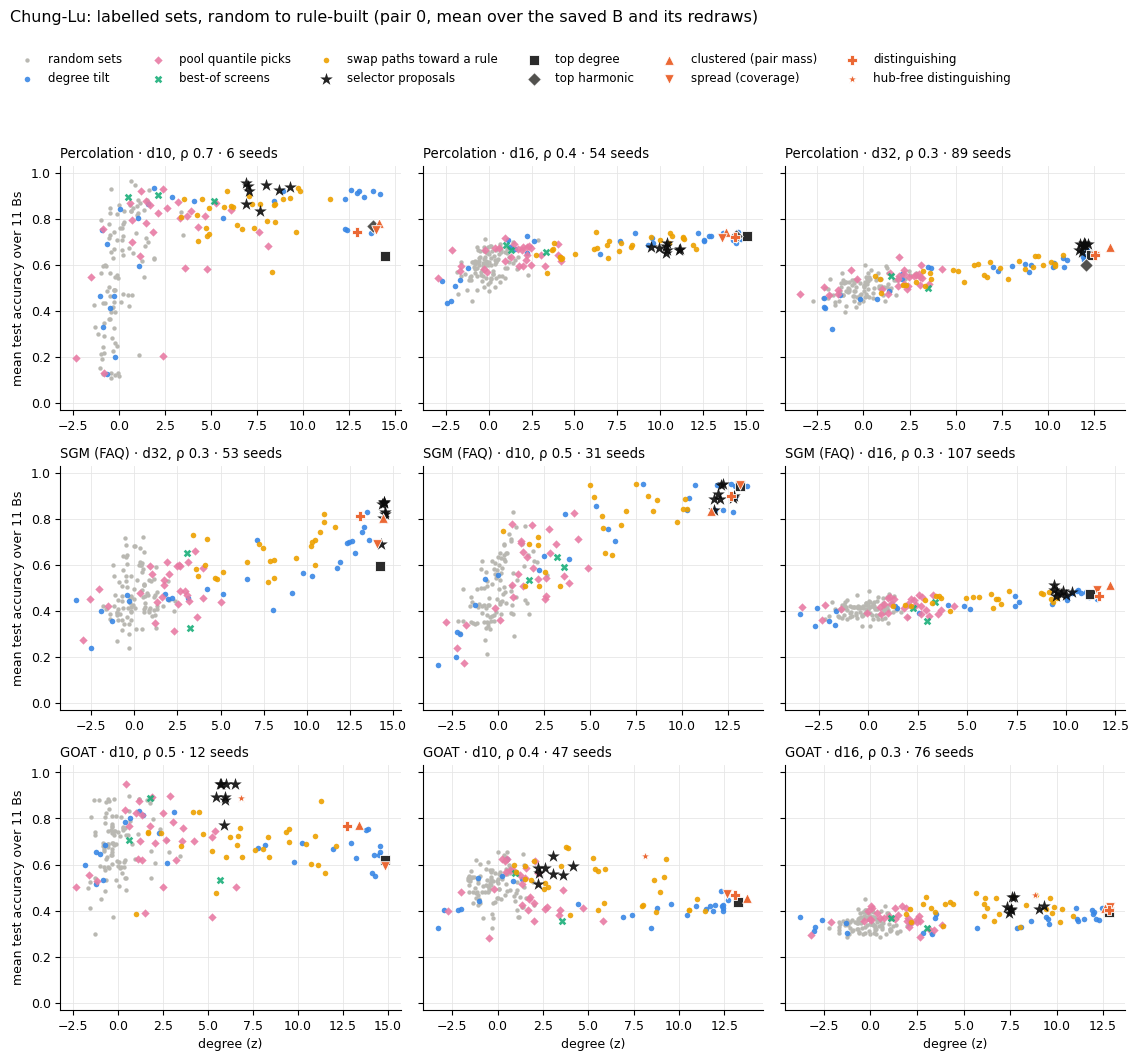

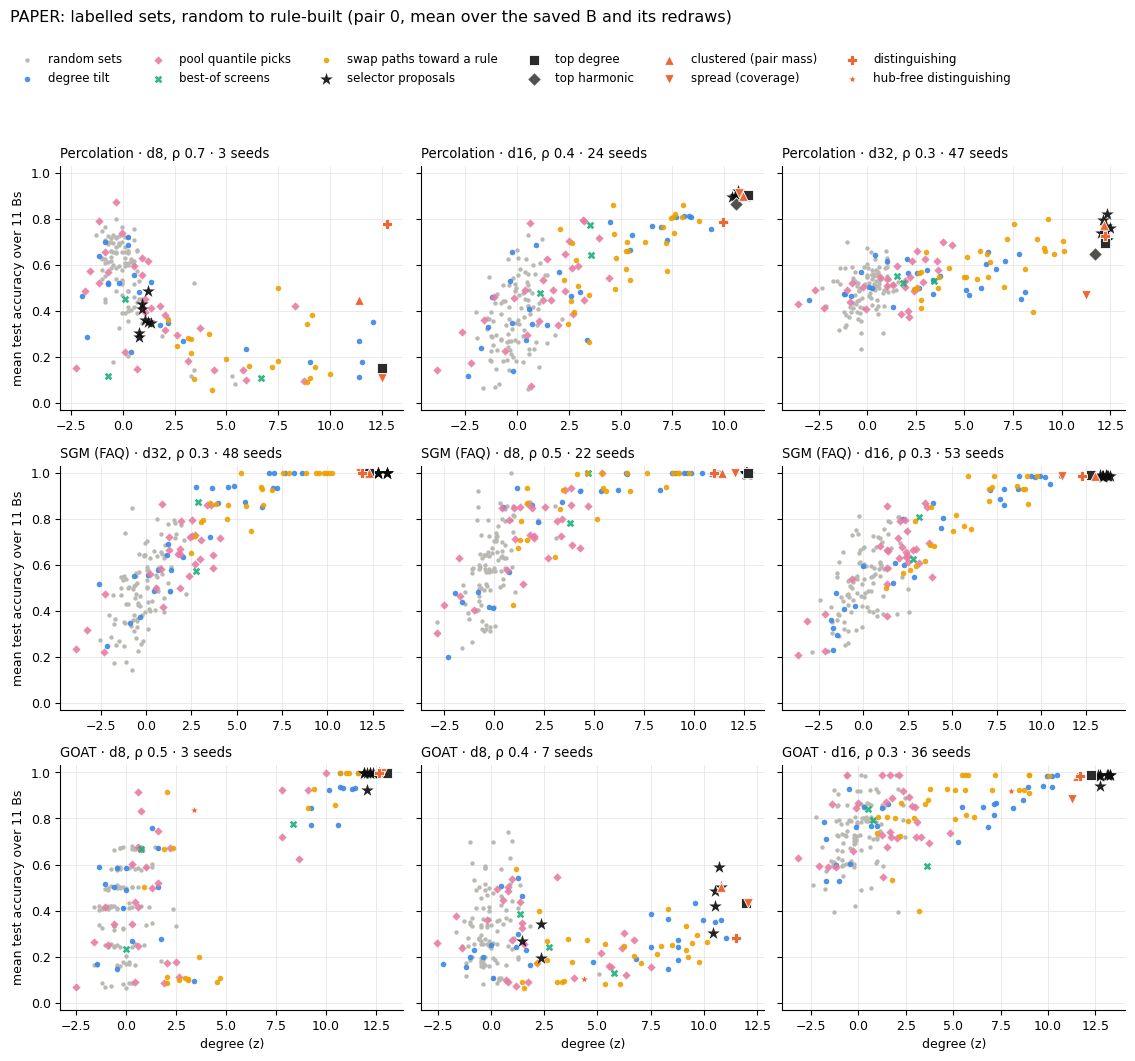

In [5]:
labelled = LS.read_training(design)
if labelled.empty:
    print("Step 2 has not run yet: python -m selection_rule_comparison.learned_selector --step constructed")
else:
    print(labelled.groupby("family").size().rename("labelled sets").to_string())
    for model in LS.MODELS:
        if (labelled["model"] == model).any():
            LS.plot_constructed(labelled, model)
            plt.show()

**Rules over the 11 Bs.** How often does a good rule fail on an unlucky B? *Took off* is the share of Bs on which the rule's single run reached test accuracy 0.8 or more; *worst B* is its lowest accuracy over the 11 Bs.

In [6]:
if not labelled.empty:
    display(LS.show(LS.resilience_table(labelled)))

rule  mean over Bs  took off (share of Bs)  worst B  SD over Bs  random sets: mean  random sets: took off
model    algorithm   mean degree ρ   budget                                                                                                                              
ER       Percolation 8           0.7 13                   top degree          0.94                    1.00     0.88        0.03               0.45                   0.24
                                     13                 top harmonic          0.87                    0.91     0.27        0.20               0.45                   0.24
                                     13        clustered (pair mass)          0.87                    0.91     0.19        0.23               0.45                   0.24
                                     13            spread (coverage)          0.94                    1.00     0.87        0.04               0.45                   0.24
                                     13               distinguishing          0.93                    1.00     0.90        0.02               0.45                   0.24
                     16          0.4 51                   top degree          0.69                    0.18     0.42        0.13               0.54                   0.09
                                     51                 top harmonic          0.69                    0.18     0.44        0.12               0.54                   0.09
                                     51        clustered (pair mass)          0.72                    0.27     0.51        0.11               0.54                   0.09
                                     51            spread (coverage)          0.65                    0.18     0.18        0.18               0.54                   0.09
                                     51               distinguishing          0.75                    0.36     0.56        0.10               0.54                   0.09
                     32          0.3 93                   top degree          0.74                    0.36     0.49        0.11               0.66                   0.23
                                     93                 top harmonic          0.78                    0.55     0.67        0.06               0.66                   0.23
                                     93        clustered (pair mass)          0.78                    0.55     0.67        0.10               0.66                   0.23
                                     93            spread (coverage)          0.73                    0.45     0.52        0.12               0.66                   0.23
                                     93               distinguishing          0.73                    0.55     0.50        0.13               0.66                   0.23
         SGM (FAQ)   8           0.5 58                   top degree          0.81                    0.73     0.42        0.18               0.45                   0.25
                                     58        clustered (pair mass)          0.82                    0.73     0.43        0.19               0.45                   0.25
                                     58            spread (coverage)          0.89                    0.91     0.57        0.12               0.45                   0.25
                                     58               distinguishing          0.89                    0.91     0.50        0.13               0.45                   0.25
                     16          0.3 143                  top degree          0.63                    0.09     0.46        0.13               0.63                   0.20
                                     143       clustered (pair mass)          0.70                    0.18     0.57        0.10               0.63                   0.20
                                     143           spread (coverage)          0.64                    0.09     0.48        0.12               0.63        

## 3. The selector and its rounds (step 3)

**Coefficients** of each cell's final selector, per SD of each term over the cell's labelled sets (logit scale), with its in-sample fit.

**Leave one family out.** Fit without one kind of set, then predict that kind. A selector that predicts the rules' quality without having seen them (MAE, Spearman) has learned something that carries beyond its data. The frozen score's ranking of the same sets is shown for comparison. *Share in range* is how many of the held-out sets lie inside the other sets' range of z-scores.

In [7]:
coefficients = LS.coefficient_table(design)
if coefficients.empty:
    print("No final selectors yet: run the rounds and --step finalize (or --all).")
else:
    display(LS.show(coefficients))
    display(LS.show(LS.lofo_table(design)))

sets  in-sample Spearman  in-sample MAE  z_degree  z_harmonic  z_pair_mass  z_uniqueness  z_degree_sq
model    algorithm   mean degree ρ   budget                                                                                                       
ER       Percolation 8           0.7 13       203                0.86           0.09      0.01        0.58         0.39          0.14        -0.12
                     16          0.4 51       202                0.74           0.05      0.21        0.10         0.12          0.00        -0.17
                     32          0.3 93       203                0.66           0.03      0.12        0.01         0.10          0.00        -0.06
         SGM (FAQ)   8           0.5 58       195                0.89           0.06      0.50        0.32         0.02          0.10        -0.21
                     16          0.3 143      195                0.53           0.02      0.12       -0.09         0.05          0.03        -0.05
                     32          0.3 71       195                0.75           0.07      0.30       -0.03         0.35          0.03         0.24
         GOAT        8           0.4 105      203                0.77           0.02      0.22       -0.03        -0.05         -0.00        -0.02
                                 0.5 33       203                0.91           0.06      0.47        0.36         0.07          0.10        -0.25
                     16          0.3 117      203                0.62           0.02      0.15       -0.07         0.06          0.00        -0.03
Chung-Lu Percolation 10          0.7 6        203                0.76           0.11     -0.12        1.16         0.47          0.13        -0.96
                     16          0.4 54       203                0.74           0.04      0.17        0.15        -0.01          0.02        -0.12
                     32          0.3 89       202                0.79           0.03      0.05        0.06         0.17          0.00        -0.06
         SGM (FAQ)   10          0.5 31       196                0.84           0.08      0.29        0.51         0.02          0.31        -0.27
                     16          0.3 107      196                0.63           0.02      0.02        0.06         0.04         -0.00        -0.02
                     32          0.3 53       195                0.63           0.08      0.02        0.21         0.23         -0.08         0.05
         GOAT        10          0.4 47       202                0.56           0.06     -0.26        0.21         0.03          0.07        -0.11
                                 0.5 12       203                0.57           0.08     -0.46        0.33         0.25          0.40        -0.43
                     16          0.3 76       202                0.46           0.03      0.01        0.07         0.06          0.00        -0.06
PAPER    Percolation 8           0.7 3        185                0.66           0.12     -0.90       -0.06        -0.06          0.03         0.51
                     16          0.4 24       203                0.77           0.10      0.03        0.41         0.49          0.00        -0.08
                     32          0.3 47       203                0.53           0.06      0.08       -0.04         0.25         -0.00        -0.01
         SGM (FAQ)   8           0.5 22       195                0.84           0.09      0.96        0.14        -0.06          0.42         0.27
                     16          0.3 53       195                0.83           0.08      0.40        0.09         0.15          0.53         0.14
                     32          0.3 48       195                0.86           0.08      0.48        0.42         0.32          0.09         0.44
         GOAT        8           0.4 7        203                0.28           0.11     -0.38       -0.18         0.14          0.18         0.29
                                 0.5 3        191                0.51       

held out  sets  observed mean  predicted mean   MAE  Spearman  frozen score Spearman  share in range
model    algorithm   mean degree ρ   budget                                                                                                      
ER       Percolation 8           0.7 13          path    30           0.69            0.73  0.12      0.77                   0.73            1.00
                                     13      proposal     8           0.90            0.98  0.08      0.60                   0.57            0.50
                                     13      quantile    29           0.61            0.59  0.09      0.71                   0.77            0.93
                                     13        random   100           0.45            0.46  0.10      0.67                   0.74            1.00
                                     13          rule     5           0.91            0.90  0.06     -0.90                  -0.30            0.20
                                     13        screen     3           0.84            0.72  0.14      1.00                   1.00            1.00
                                     13          tilt    28           0.65            0.62  0.08      0.87                   0.87            1.00
                     16          0.4 51          path    30           0.66            0.64  0.03      0.50                   0.52            1.00
                                     51      proposal     8           0.68            0.79  0.10     -0.31                  -0.62            1.00
                                     51      quantile    29           0.55            0.56  0.05      0.75                   0.81            0.90
                                     51        random   100           0.54            0.54  0.06      0.35                   0.44            1.00
                                     51          rule     5           0.70            0.67  0.03      0.30                   0.90            0.00
                                     51          tilt    28           0.60            0.60  0.04      0.80                   0.80            1.00
                     32          0.3 93          path    30           0.72            0.72  0.02      0.75                   0.74            1.00
                                     93      proposal     8           0.78            0.78  0.02      0.18                   0.10            0.50
                                     93      quantile    29           0.68            0.67  0.03      0.54                   0.53            0.93
                                     93        random   100           0.66            0.67  0.04      0.33                   0.31            1.00
                                     93          rule     5           0.75            0.76  0.02      0.00                   0.00            0.20
                                     93        screen     3           0.68            0.69  0.02      0.50                  -0.50            1.00
                                     93          tilt    28           0.68            0.69  0.03      0.63                   0.64            1.00
         SGM (FAQ)   8           0.5 58          path    24           0.71            0.71  0.05      0.83                   0.78            1.00
                                     58      proposal     8           0.86            0.90  0.04     -0.50                   0.26            1.00
                                     58      quantile    29           0.55            0.53  0.07      0.73                   0.76            1.00
                                     58        random   100           0.45            0.47  0.06      0.62                   0.60            1.00
                                     58          rule     4           0.85            0.85  0.05     -0.40                  -0.20            0.75
                                     58          tilt    28           0.62            0.63  0.05      0

**Proposals per round** on pair 0, against the best rule and the best set labelled before the round, on the same 11 Bs.

The selector has seen these Bs' other sets, so this checks the loop. It is not the test; step 4 is.

In [8]:
if not labelled.empty and (labelled["family"] == "proposal").any():
    display(LS.show(LS.proposal_table(labelled)))
else:
    print("No proposals yet: python -m selection_rule_comparison.learned_selector --step round --round 1")

proposals  sets  best observed  mean observed                best rule  best rule observed  best labelled before
model    algorithm   mean degree ρ   budget                                                                                                                   
ER       Percolation 8           0.7 13      exploit r1     2           0.93           0.87        spread (coverage)                0.94                  0.96
                                     13      exploit r2     2           0.94           0.94        spread (coverage)                0.94                  0.96
                                     13      explore r1     2           0.87           0.86        spread (coverage)                0.94                  0.96
                                     13      explore r2     2           0.94           0.91        spread (coverage)                0.94                  0.96
                     16          0.4 51      exploit r1     2           0.72           0.69           distinguishing                0.75                  0.75
                                     51      exploit r2     2           0.70           0.69           distinguishing                0.75                  0.75
                                     51      explore r1     2           0.68           0.68           distinguishing                0.75                  0.75
                                     51      explore r2     2           0.68           0.68           distinguishing                0.75                  0.75
                     32          0.3 93      exploit r1     2           0.77           0.77             top harmonic                0.78                  0.79
                                     93      exploit r2     2           0.80           0.78             top harmonic                0.78                  0.80
                                     93      explore r1     2           0.80           0.78             top harmonic                0.78                  0.79
                                     93      explore r2     2           0.79           0.78             top harmonic                0.78                  0.80
         SGM (FAQ)   8           0.5 58      exploit r1     2           0.89           0.84        spread (coverage)                0.89                  0.89
                                     58      exploit r2     2           0.87           0.87        spread (coverage)                0.89                  0.89
                                     58      explore r1     2           0.88           0.88        spread (coverage)                0.89                  0.89
                                     58      explore r2     2           0.86           0.85        spread (coverage)                0.89                  0.89
                     16          0.3 143     exploit r1     2           0.72           0.72    clustered (pair mass)                0.70                  0.74
                                     143     exploit r2     2           0.73           0.72    clustered (pair mass)                0.70                  0.74
                                     143     explore r1     2           0.70           0.69    clustered (pair mass)                0.70                  0.74
                                     143     explore r2     2           0.75           0.74    clustered (pair mass)                0.70                  0.74
                     32          0.3 71      exploit r1     2           1.00           1.00    clustered (pair mass)                1.00                  1.00
                                     71      exploit r2     2           1.00           1.00    clustered (pair mass)                1.00                  1.00
                                     71      explore r1     2           1.00           0.97    clustered (pair mass)                1.00                  1.00
                                     71      explore r2     2          

### 3.1 Final selector predictions on the training sets

Each panel uses that setting's **saved final selector**, with no refitting. The x-axis is predicted mean matching accuracy; the y-axis is the observed mean over the same 11 Bs used in training. Colours and shapes match section 2. The dashed line is **y = x**: points above it performed better than predicted, and points below it performed worse.

These are **in-sample diagnostics**, including both rounds of proposals. A clear pattern here describes fit to one A and its Bs; the fresh-pair plots in section 4.1 assess generalization. The original cut-degree plots remain in section 2 for interpreting seed structure.

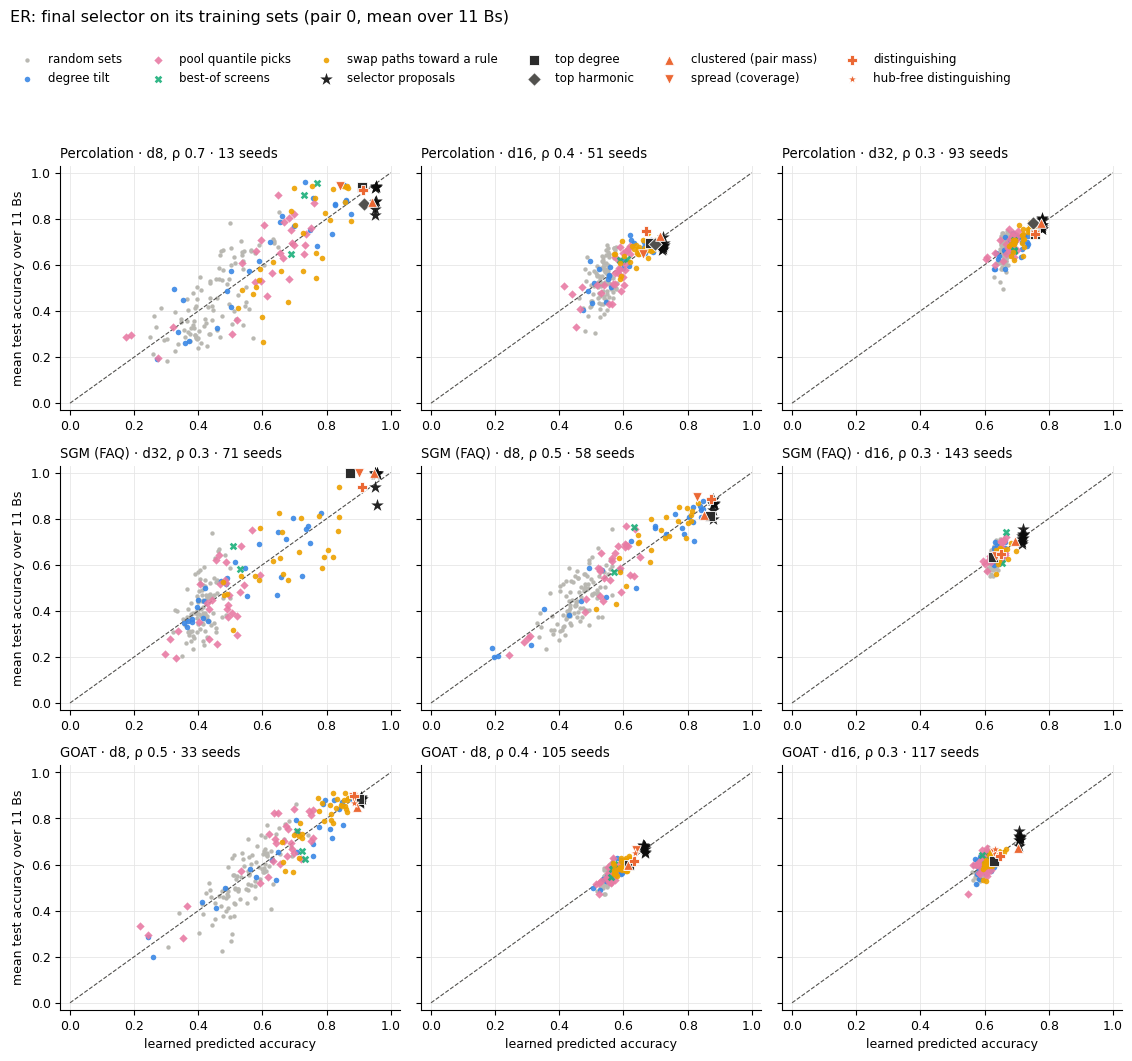

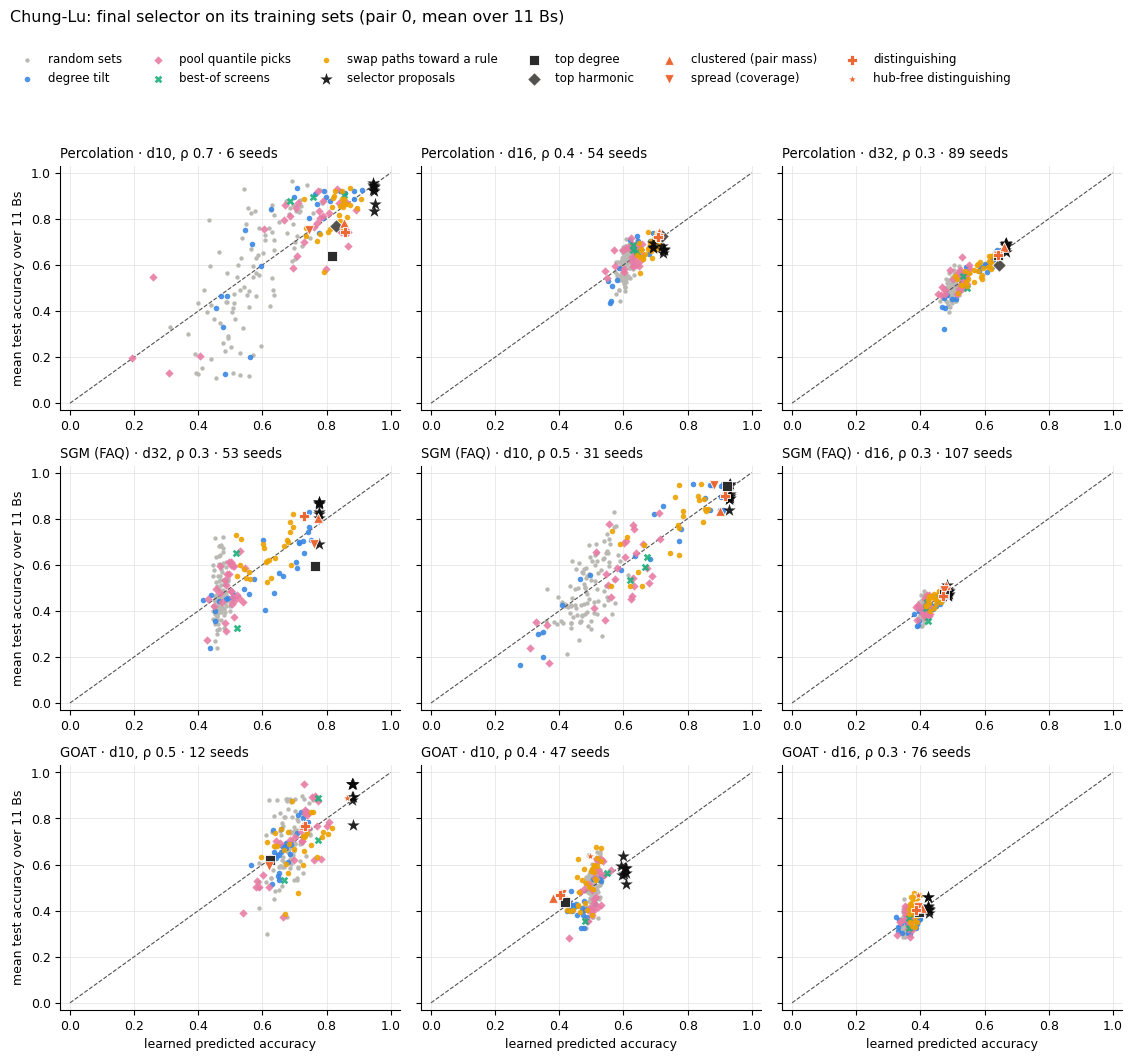

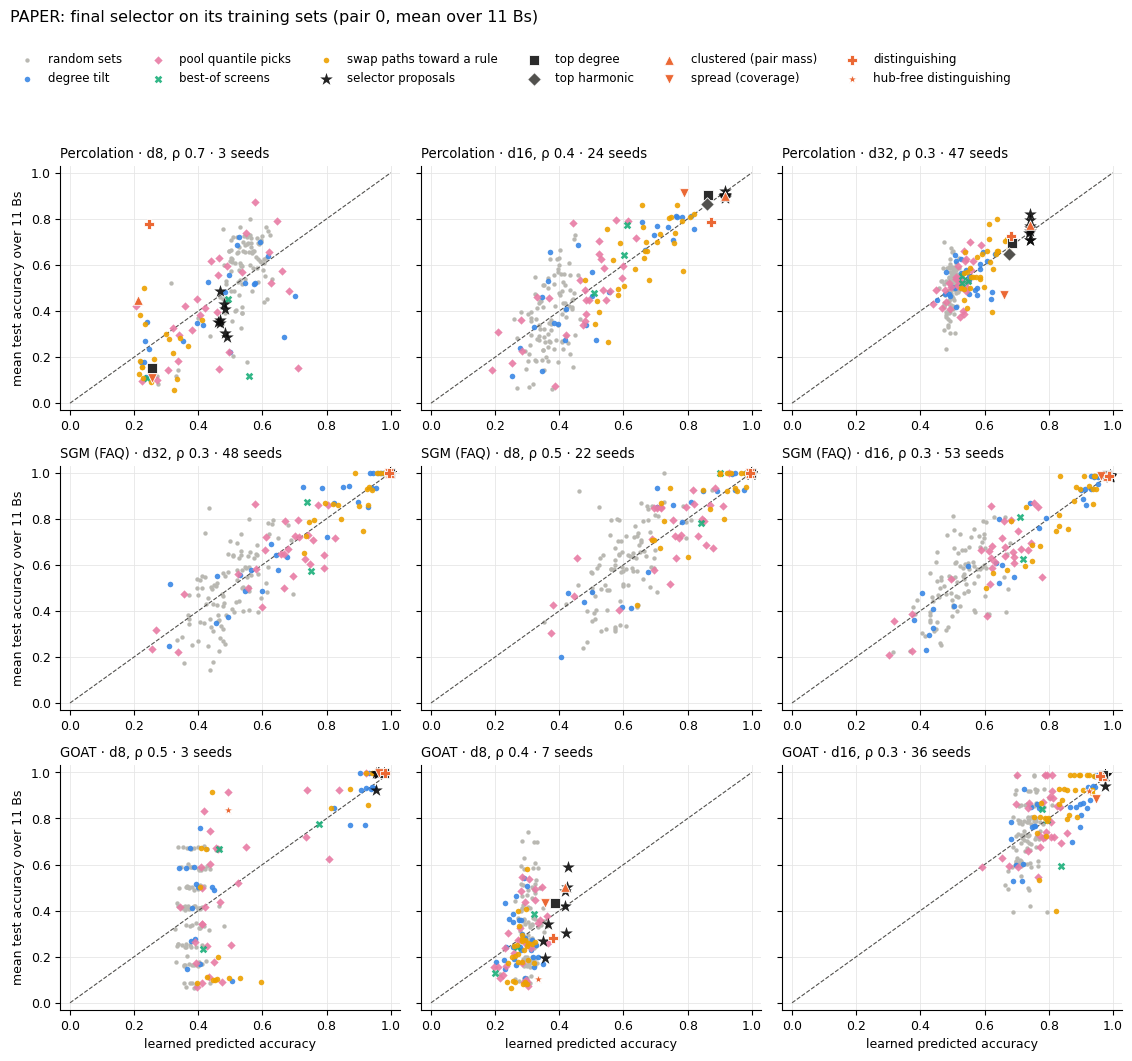

In [9]:
PREDICTION_FIGURES = Path(design["output_dir"]) / "figures"

if labelled.empty:
    print("No labelled training sets yet.")
else:
    training_predictions = LS.add_final_predictions(labelled, design)
    PREDICTION_FIGURES.mkdir(parents=True, exist_ok=True)
    for model in LS.MODELS:
        part = training_predictions[training_predictions["model"] == model].dropna(subset=["predicted_accuracy"])
        if not part.empty:
            fig = LS.plot_constructed(part, model, x="predicted_accuracy")
            for suffix in ("png", "pdf"):
                fig.savefig(PREDICTION_FIGURES / f"{model}_training_predictions.{suffix}", dpi=180)
            plt.show()

## 4. Fresh pairs: the test (step 4)

Ten new pairs per cell at the same k. Each set's accuracy is averaged over the pair's saved B and 4 redraws (random sets: saved B only), then over pairs.
- The best rule was fixed in advance from the landscape's five pairs (`best_rules.json`).
- **learned − best rule** and **frozen_built − best rule** are paired differences over the fresh pairs, with 95% intervals.
- **won/tied/lost** counts pairs, with ties within 0.01.

pairs                best rule  random  best_1000  frozen_built  best_rule  learned  learned − best rule  learned − best rule, 95% low  learned − best rule, 95% high learned: won/tied/lost  \
model    algorithm   mean degree ρ   budget                                                                                                                                                                                                 
ER       Percolation 8           0.7 13         10             top harmonic    0.48       0.77          0.94       0.92     0.93                 0.02                         -0.01                           0.04                  4/5/1   
                     16          0.4 51         10    clustered (pair mass)    0.51       0.57          0.70       0.70     0.67                -0.03                         -0.04                          -0.01                  2/0/8   
                     32          0.3 93         10               top degree    0.65       0.70          0.79       0.77     0.80                 0.03                          0.01                           0.05                  7/1/2   
         SGM (FAQ)   8           0.5 58         10        spread (coverage)    0.40       0.72          0.87       0.85     0.86                 0.01                         -0.01                           0.03                  4/4/2   
                     16          0.3 143        10    clustered (pair mass)    0.58       0.61          0.70       0.68     0.68                -0.00                         -0.02                           0.02                  4/2/4   
                     32          0.3 71         10    clustered (pair mass)    0.40       0.68          0.94       0.94     0.96                 0.02                         -0.03                           0.07                  3/6/1   
         GOAT        8           0.4 105        10        spread (coverage)    0.53       0.54          0.62       0.62     0.66                 0.04                          0.02                           0.07                  9/0/1   
                                 0.5 33         10               top degree    0.41       0.78          0.90       0.88     0.86                -0.02                         -0.04                           0.00                  3/2/5   
                     16          0.3 117        10           distinguishing    0.53       0.54          0.64       0.61     0.65                 0.05                          0.03                           0.06                  9/1/0   
Chung-Lu Percolation 10          0.7 6          10    clustered (pair mass)    0.56       0.83          0.91       0.93     0.91                -0.03                         -0.07                           0.01                  1/4/5   
                     16          0.4 54         10    clustered (pair mass)    0.50       0.57          0.67       0.65     0.60                -0.06                         -0.09                          -0.02                  1/2/7   
                     32          0.3 89         10    clustered (pair mass)    0.47       0.54          0.65       0.64     0.66                 0.02                         -0.02                           0.06                  7/0/3   
         SGM (FAQ)   10          0.5 31         10        spread (coverage)    0.55       0.68          0.93       0.94     0.93                -0.01                         -0.03                           0.01                  1/7/2   
                     16          0.3 107        10    clustered (pair mass)    0.39       0.40          0.40       0.46     0.45                -0.01                         -0.04                           0.02                  5/0/5   
                     32          0.3 53         10    clustered (pair mass)    0.43       0.64          0.52       0.75     0.76                 0.01                         -0.08                           0.09                  6/1/3   
         GOAT   

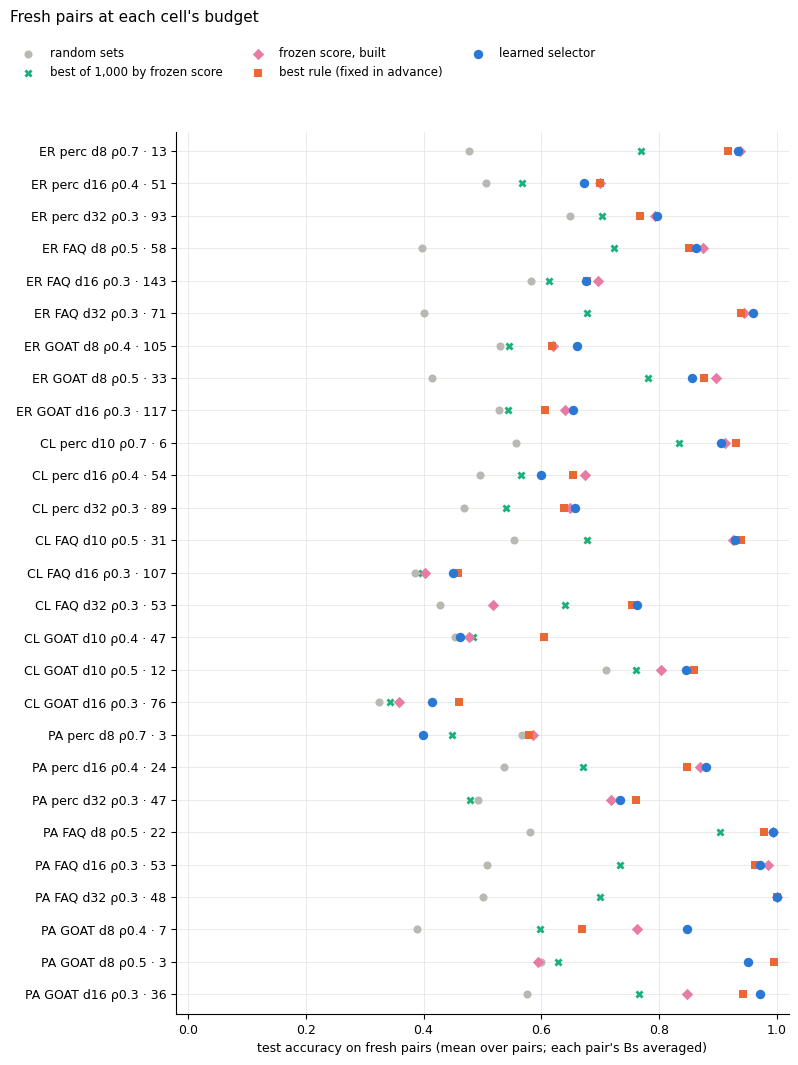

In [10]:
fresh = LS.read_fresh(design)
if fresh.empty:
    print("Step 4 has not run yet: python -m selection_rule_comparison.learned_selector --step fresh")
else:
    results = LS.fresh_table(fresh, design)
    display(LS.show(results))
    LS.plot_fresh(results)
    plt.show()

### 4.1 Fresh pairs: learned predictions and frozen score on the same sets

For each setting, the **left column** plots the saved final selector's predicted mean accuracy against observed test accuracy. The **right column** plots the frozen weighted score against the **same observed outcomes for exactly the same evaluated strategy outputs**. Each point is one strategy's seed set on one fresh pair; the ten fresh pairs are pooled within a panel. No model is refitted on these pairs.

- Coloured strategy sets are averaged over **five Bs** per pair. Grey random sets were evaluated on **one B**, so their outcomes are noisier. They retain the broader random-set context without implying five-draw averaging.
- The left column's dashed **y = x** line checks numerical calibration. The frozen score is a weighted feature sum, not an accuracy prediction, so a calibration diagonal does not apply to the right column.
- Colours and shapes identify how sets were selected, not which model scores them: **every set is scored by both models**. If several strategies selected identical vertices, their separately saved evaluations remain visible under their respective strategies.
- These plots show prediction behaviour on the evaluated candidates. The paired strategy comparisons in section 4 remain the direct test of selection performance. Pooling pairs also includes differences in graph-pair difficulty.

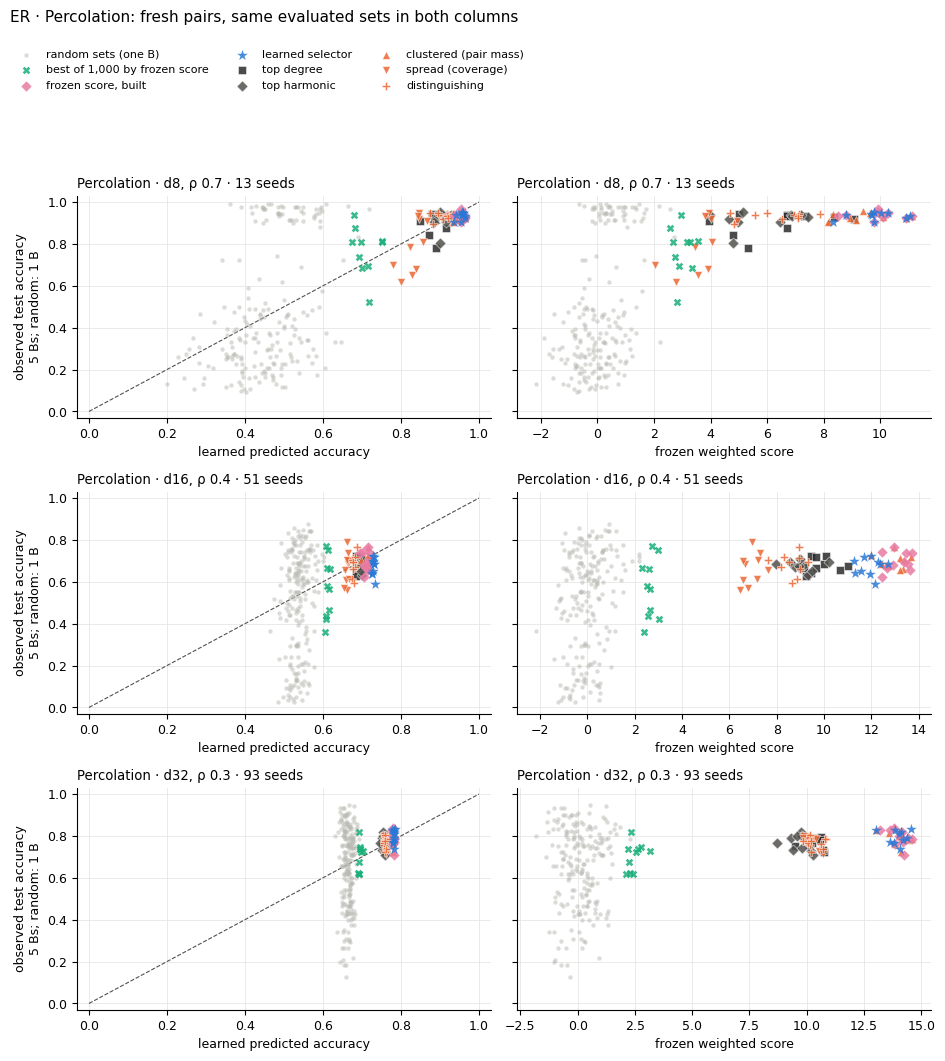

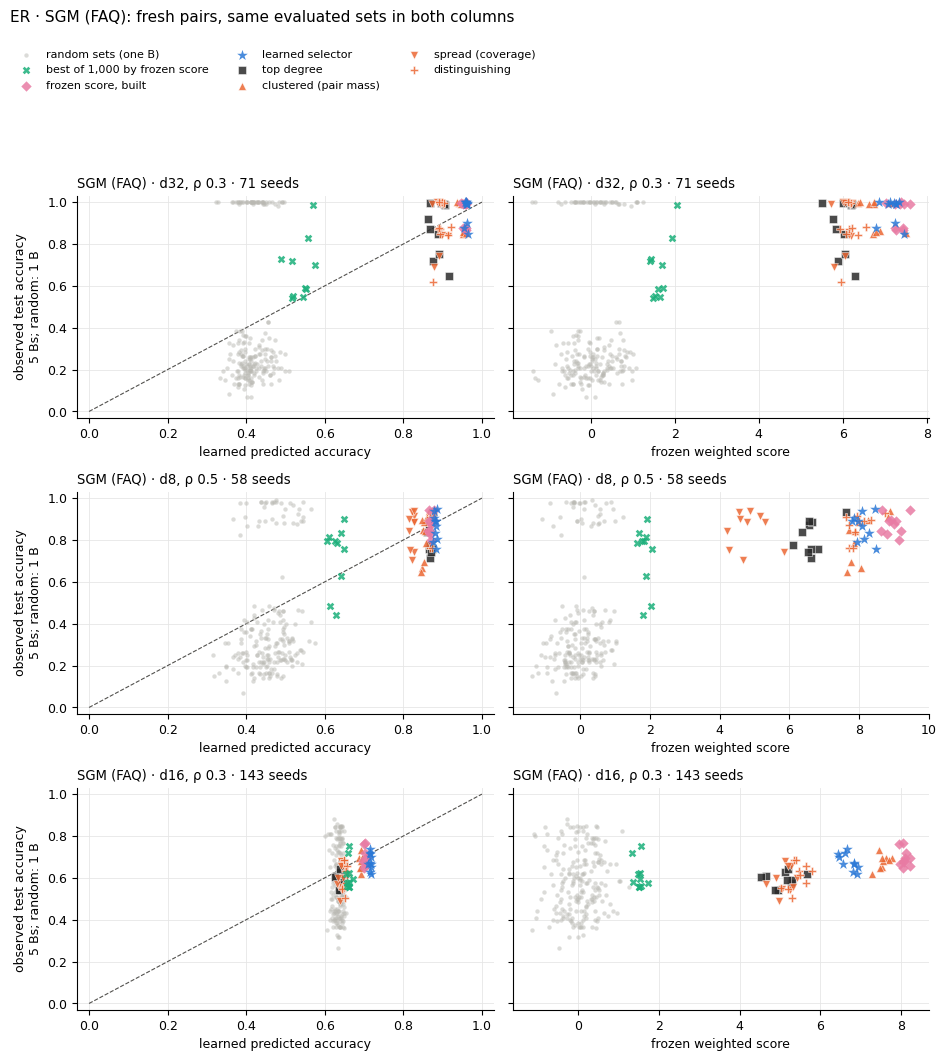

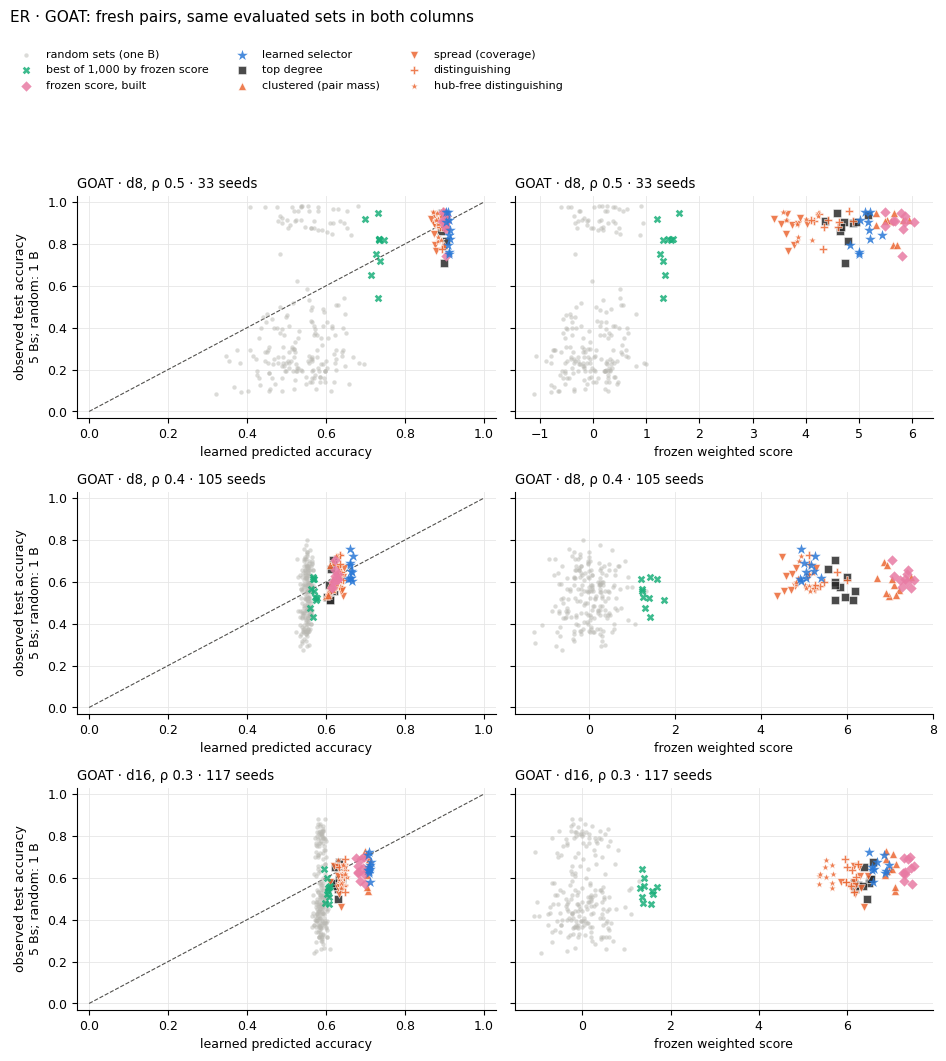

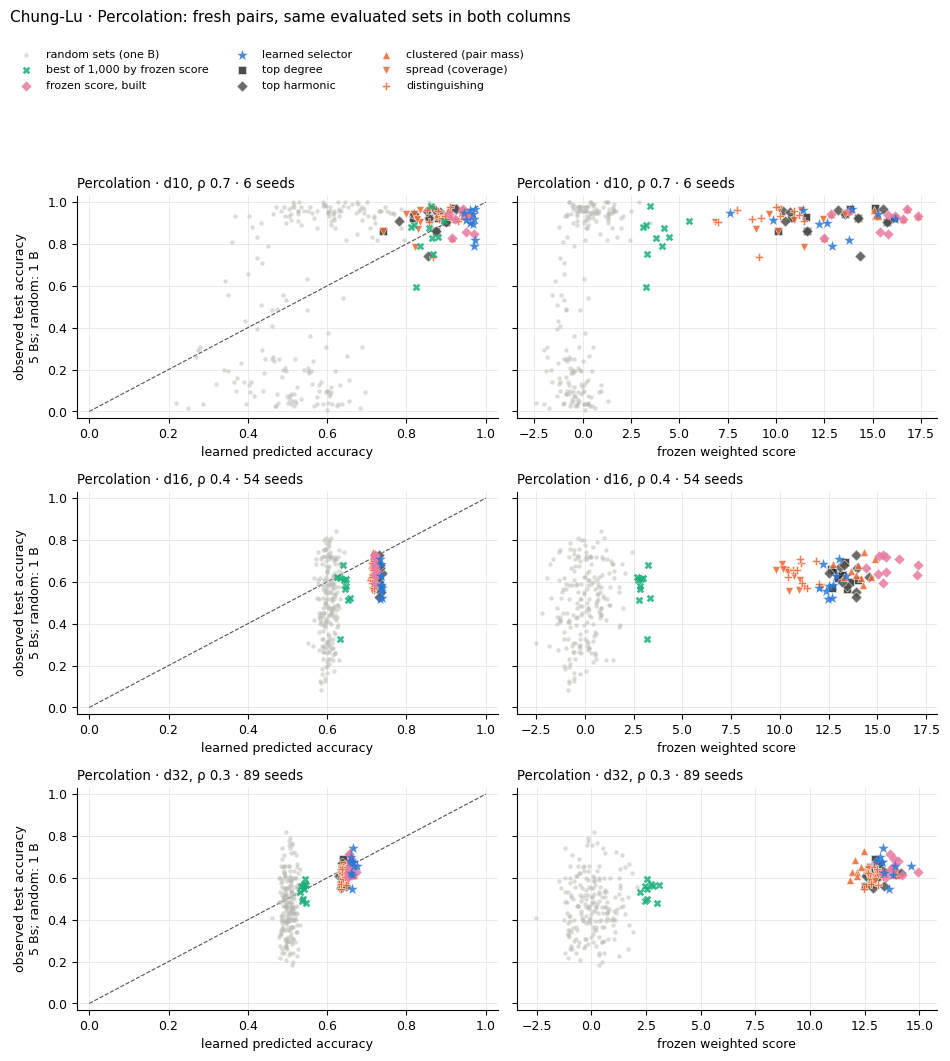

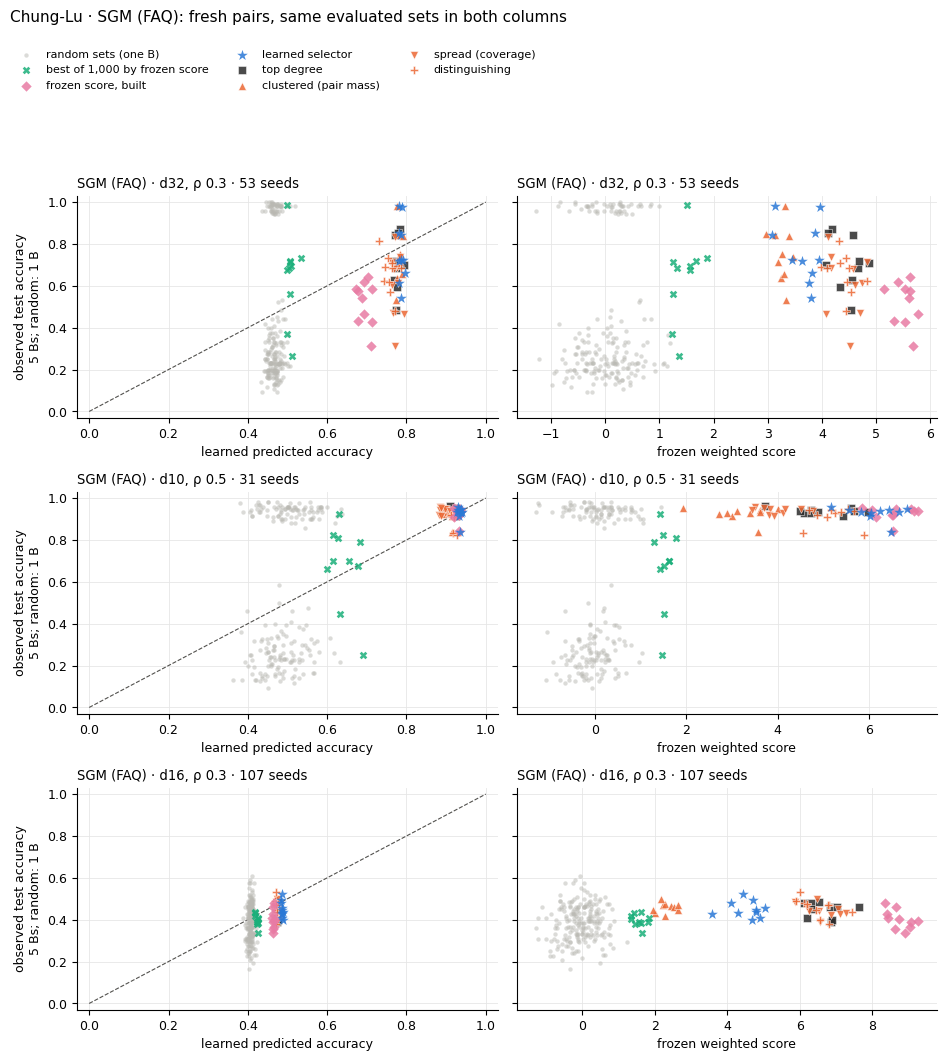

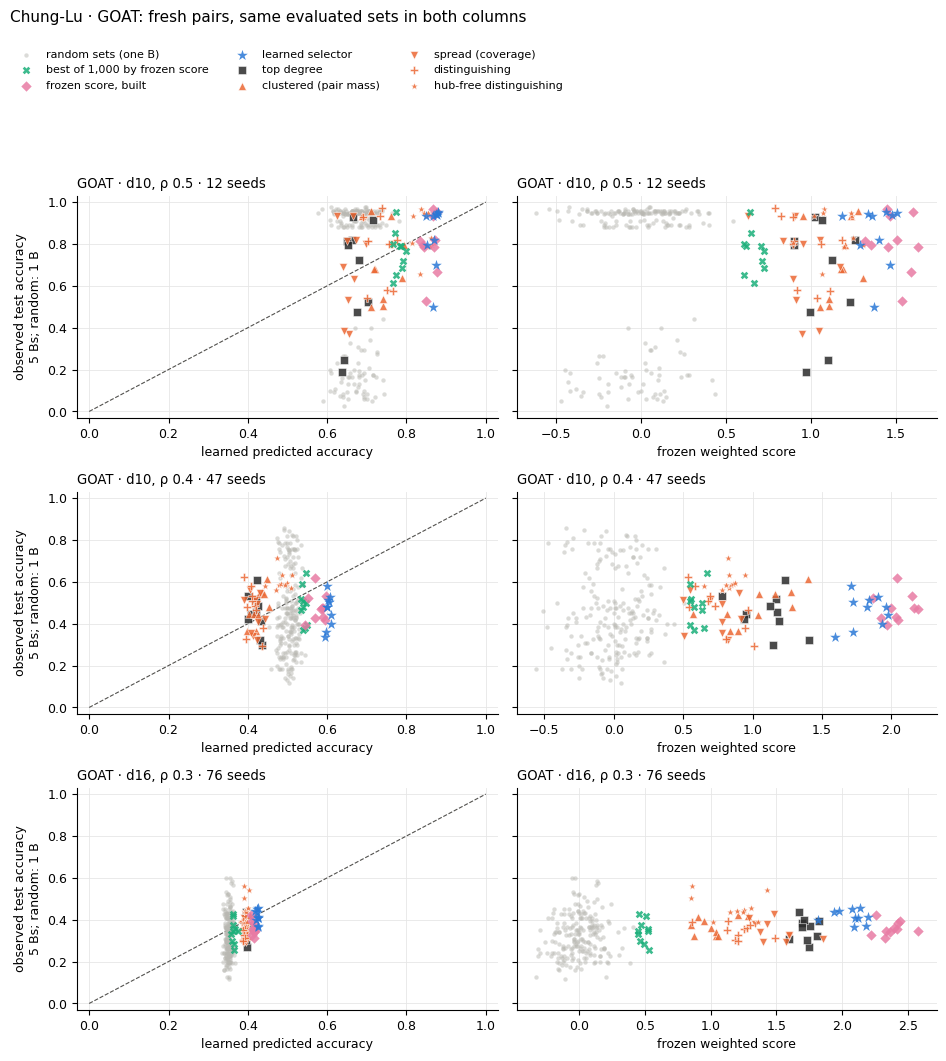

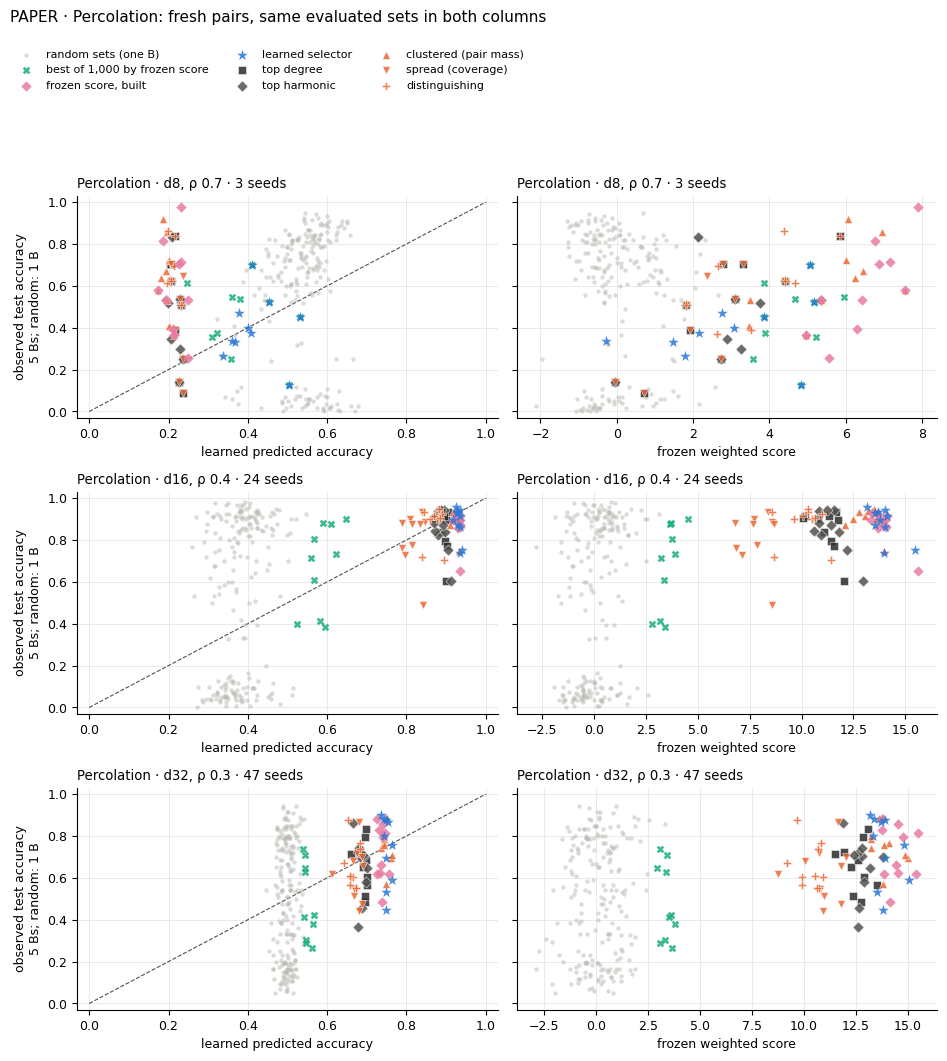

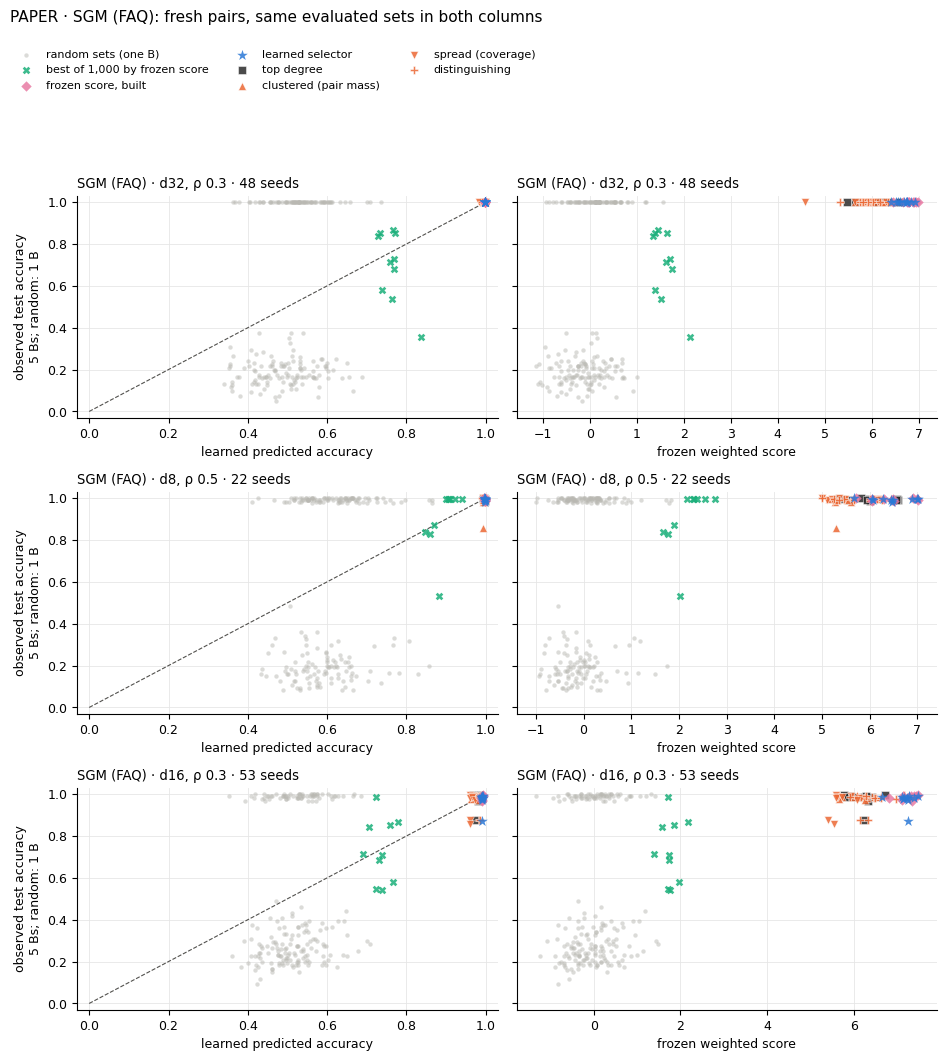

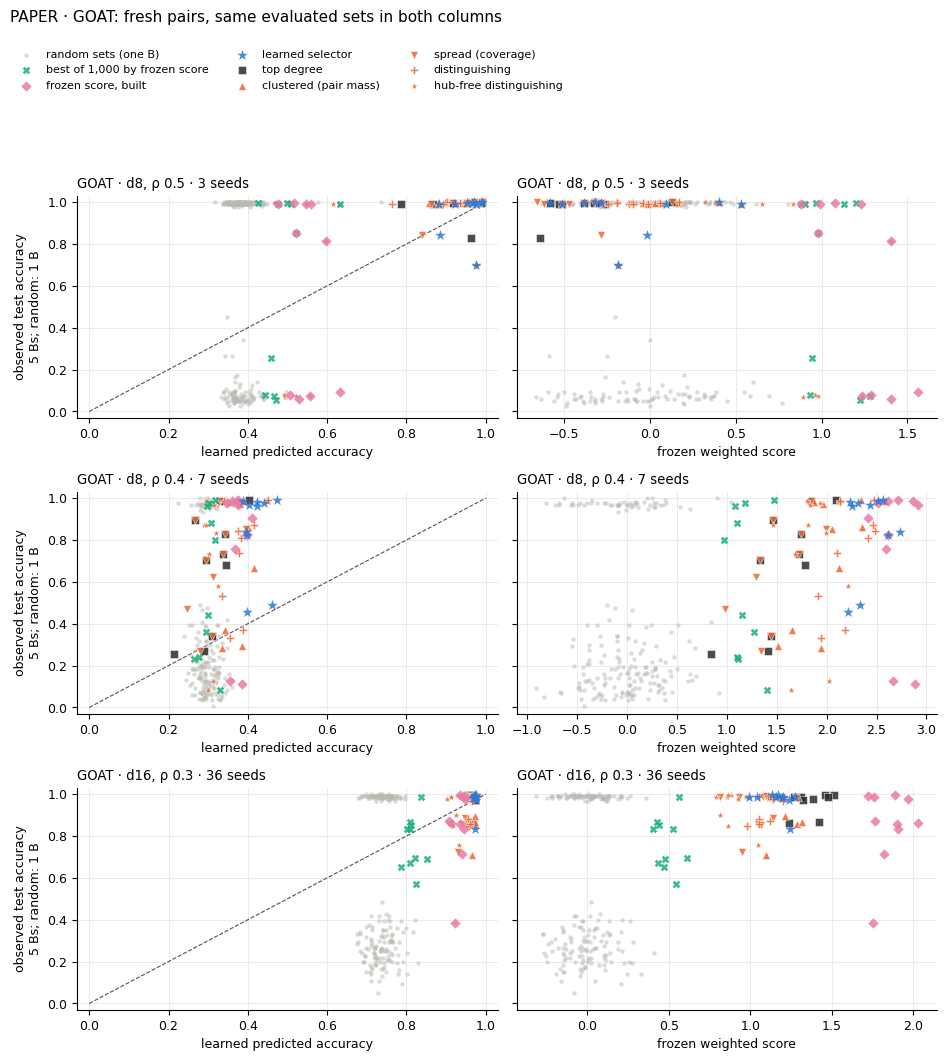

In [11]:
if fresh.empty:
    print("No fresh-pair results yet.")
else:
    fresh_predictions = LS.add_final_predictions(fresh, design)
    PREDICTION_FIGURES = Path(design["output_dir"]) / "figures"
    PREDICTION_FIGURES.mkdir(parents=True, exist_ok=True)
    for model in LS.MODELS:
        for algorithm in LS.ALGORITHMS:
            fig = LS.plot_fresh_predictions(fresh_predictions, model, algorithm)
            if fig is not None:
                for suffix in ("png", "pdf"):
                    fig.savefig(PREDICTION_FIGURES / f"{model}_{algorithm}_fresh_predictions.{suffix}", dpi=180)
                plt.show()

## Reading the results

- **Step 2.** If quality keeps rising along the tilts and swap paths up to the rules, degree-like structure is what matters, and the selector should sit near top degree. Look for a turn or plateau before the rules, or rules sitting off the trend of the other constructed sets: those are where a learned selector could beat them. Also check how often the rules fail on an unlucky B.
- **Step 3.** The leave-one-family-out rows for *rule* and *path* tell whether the selector predicts sets it has not seen. Large errors there mean step 4's gains or losses come from the guard and the search start points (the rules), not from the fit.
- **Step 4 is the answer.** A positive *learned − best rule* whose interval excludes 0, in cells beyond those where the rules already reach the ceiling, would show that a fitted selector improves on the best hand-made rule at the same k. *frozen_built* shows how much of that comes from fitting in the right region rather than from searching near the rules.
- **Caveat.** "Best rule" is fixed from five landscape pairs, so in cells where rules tie it can be a near-random pick among equals; compare with every rule's column in `LS.read_fresh()`.